## Regress for LW/SW with unit vertical motions

### Import package

In [26]:
import numpy as np

from scipy.interpolate import interp1d

from matplotlib import pyplot as plt
from matplotlib.colors import TwoSlopeNorm

### Load data

In [27]:
# Load Jacobian matrices. They map 15-level geometric vertical velocity
# (m s^-1) to 15-level radiative-heating anomalies (assumed K day^-1).
J_LW: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/Jacob_LW.txt")
J_SW: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/Jacob_SW.txt")

# Load pressure levels (Pa).
plev: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/plev.txt")

assert plev.ndim == 1 and np.all(np.diff(plev) > 0)
assert J_LW.shape == J_SW.shape == (plev.size, plev.size)

### Design vertical profiles

In [28]:
# height coordinate in Kuang's model
z: np.ndarray = np.linspace(0, 14000, 141)

# convert height coordinate to pressure coordinate
T0     : float = 300 # surface temperature: 300 K
Gamma_T: float = 0.0065 # -d\overline{T}/dz: 0.0065
Gamma_d: float = 9.81/1004.5
p0     : float = 1e5 # surface pressure: 100000 Pa

T: np.ndarray = T0 - Gamma_T*z
p: np.ndarray = p0 * (1 - Gamma_T*z/T0) ** (9.81/287.5/Gamma_T)
rho: np.ndarray = p / 287.5 / T

# Galerkin basis. In this model normalization, G represents a unit
# density-weighted vertical-velocity (mass-flux) profile per day.
G1: np.ndarray = np.pi/2 * np.sin(np.pi*z/z.max())
G2: np.ndarray = np.pi/2 * np.sin(2*np.pi*z/z.max())

G_stack: np.ndarray = np.stack([G1, G2], axis=1)

### Calculate radiative heating

In [29]:
# Convert both density-weighted modes to geometric velocity (m s^-1).
# Columns correspond to input modes 1 and 2.
w_modes: np.ndarray = G_stack / (86400.0 * rho[:, None])

# Interpolate to the ERA5 pressure levels. Kuang's domain ends near
# 150 hPa, so impose w=0 above/below it instead of extrapolating a
# large, nonphysical value to the 100-hPa ERA5 level.
w_ERA5: np.ndarray = interp1d(
    p, w_modes, axis=0, bounds_error=False, fill_value=0.0
)(plev)  # type: ignore

# Apply each 15 x 15 Jacobian to both input modes at once.
lw_ERA5: np.ndarray = J_LW @ w_ERA5
sw_ERA5: np.ndarray = J_SW @ w_ERA5

# Interpolate the heating profiles back to Kuang's coordinate. All
# target pressures lie inside the ERA5 pressure range.
lw_modes: np.ndarray = interp1d(
    plev, lw_ERA5, axis=0, bounds_error=True
)(p)  # type: ignore
sw_modes: np.ndarray = interp1d(
    plev, sw_ERA5, axis=0, bounds_error=True
)(p)  # type: ignore

assert w_modes.shape == (z.size, 2)
assert w_ERA5.shape == lw_ERA5.shape == sw_ERA5.shape == (plev.size, 2)
assert lw_modes.shape == sw_modes.shape == (z.size, 2)

### Project radiative heating to Kuang's bases

In [30]:
# Heating basis for Q = G_J @ coefficient / rho.
# Rows of each coefficient matrix are output modes; columns are input modes.
G_J_stack: np.ndarray = G_stack * (Gamma_d - Gamma_T)

# Solve the least-squares problem directly rather than explicitly inverting
# the normal-equation matrix.
lw_coeff: np.ndarray = np.linalg.lstsq(
    G_J_stack, rho[:, None] * lw_modes, rcond=None
)[0]
sw_coeff: np.ndarray = np.linalg.lstsq(
    G_J_stack, rho[:, None] * sw_modes, rcond=None
)[0]

assert lw_coeff.shape == sw_coeff.shape == (2, 2)

In [31]:
# Reconstruct all four responses with both output basis functions.
lw_reconstructed: np.ndarray = G_J_stack @ lw_coeff / rho[:, None]
sw_reconstructed: np.ndarray = G_J_stack @ sw_coeff / rho[:, None]

# Relative errors in the same density-weighted norm minimized by the fit.
lw_relative_error: np.ndarray = np.linalg.norm(
    rho[:, None] * (lw_reconstructed - lw_modes), axis=0
) / np.linalg.norm(rho[:, None] * lw_modes, axis=0)
sw_relative_error: np.ndarray = np.linalg.norm(
    rho[:, None] * (sw_reconstructed - sw_modes), axis=0
) / np.linalg.norm(rho[:, None] * sw_modes, axis=0)

### Verify coefficient

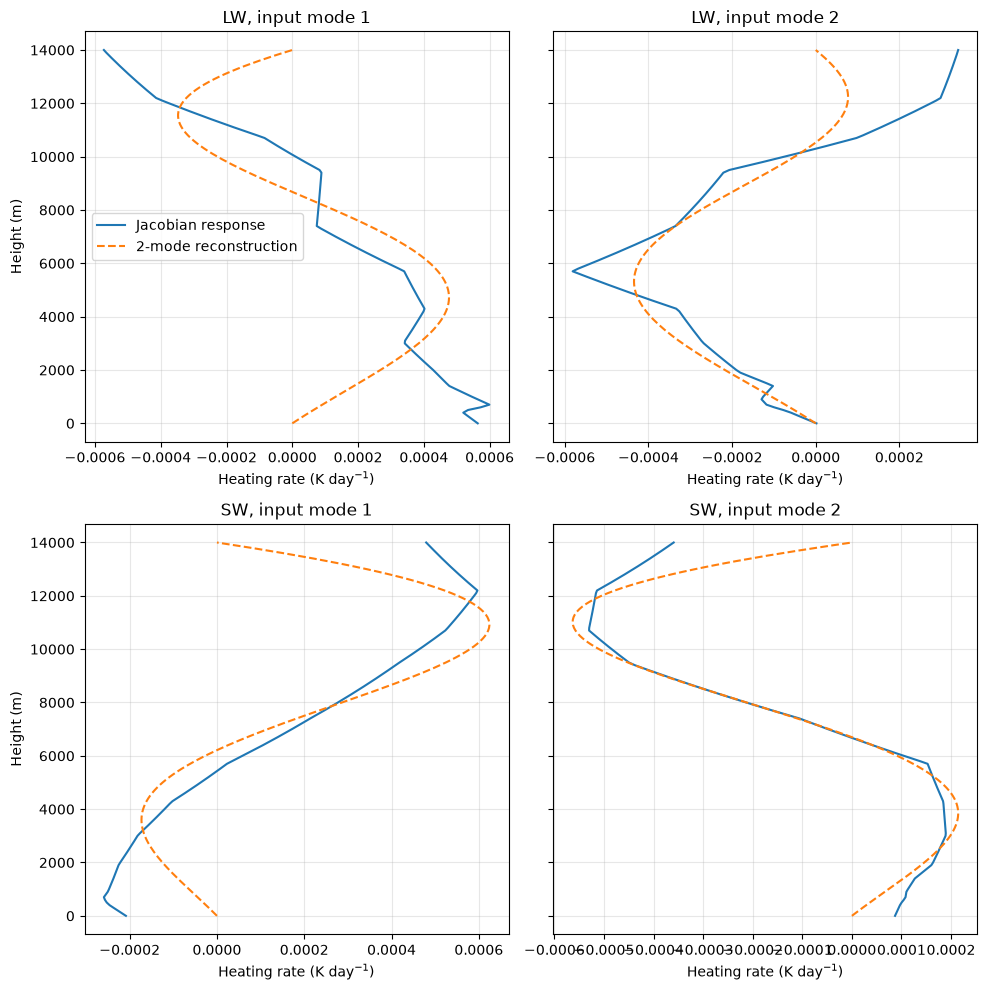

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharey=True)

for row, (radiation, original, reconstructed) in enumerate([
    ("LW", lw_modes, lw_reconstructed),
    ("SW", sw_modes, sw_reconstructed),
]):
    for mode in range(2):
        ax = axes[row, mode]
        ax.plot(original[:, mode], z, label="Jacobian response")
        ax.plot(reconstructed[:, mode], z, "--", label="2-mode reconstruction")
        ax.set_title(f"{radiation}, input mode {mode + 1}")
        ax.set_xlabel("Heating rate (K day$^{-1}$)")
        ax.grid(True, alpha=0.3)

axes[0, 0].set_ylabel("Height (m)")
axes[1, 0].set_ylabel("Height (m)")
axes[0, 0].legend()
fig.tight_layout()

In [33]:
print("LW coefficient matrix (output mode x input mode):\n", lw_coeff)
print("SW coefficient matrix (output mode x input mode):\n", sw_coeff)
print("LW relative projection error by input mode:", lw_relative_error)
print("SW relative projection error by input mode:", sw_relative_error)

LW coefficient matrix (output mode x input mode):
 [[ 0.03347541 -0.04137871]
 [ 0.04554455 -0.02905207]]
SW coefficient matrix (output mode x input mode):
 [[ 0.01304338 -0.00508454]
 [-0.03713554  0.03780223]]
LW relative projection error by input mode: [0.66674588 0.25131841]
SW relative projection error by input mode: [0.51936599 0.21086075]
